# Práctica 03: extracción de aspectos semánticos a partir de textos

## Propósito

En esta práctica se construirá un flujo de análisis semántico sin depender de modelos preentrenados ni de servicios externos. El objetivo es entender cómo surgen las relaciones entre palabras a partir del propio corpus.

Se trabajará con cuatro ideas: representación contextual de palabras, asociación mediante PMI, extracción de candidatos a términos y obtención de palabras clave con TF IDF y TextRank.

Al final se integrarán los cuatro análisis sobre un texto técnico nuevo.


## 1. Preparación del entorno

### Qué se hará

Se cargarán las bibliotecas necesarias para manejar datos, construir matrices, calcular similitud, reducir dimensiones y representar redes.

La práctica utiliza `pandas`, `numpy`, `scikit learn`, `matplotlib` y `networkx`. No necesita descargar modelos lingüísticos externos.


In [1]:
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 120)
np.random.seed(42)

print("Entorno preparado")


Entorno preparado


## 2. Corpus de trabajo

### Qué se hará

Se utilizará un corpus pequeño con textos de ciencia de datos, lenguaje natural, redes, seguridad y sistemas inteligentes.

Cada texto funciona como un documento independiente. El corpus es pequeño para que las matrices puedan revisarse durante la clase, pero contiene suficientes relaciones para observar el comportamiento de los métodos.


In [2]:
documentos = [
    "La ciencia de datos combina programación estadística análisis de datos y aprendizaje automático para resolver problemas complejos.",
    "El aprendizaje automático permite construir modelos predictivos a partir de datos históricos y variables observadas.",
    "Los modelos de clasificación asignan observaciones a clases y se evalúan mediante exactitud precisión sensibilidad y otras métricas.",
    "El procesamiento de lenguaje natural analiza textos para identificar patrones lingüísticos entidades relaciones y significado.",
    "Los modelos de lenguaje representan palabras y contextos para estimar relaciones semánticas dentro de grandes colecciones de textos.",
    "La similitud semántica permite localizar palabras que aparecen en contextos parecidos aunque no sean idénticas.",
    "La extracción de palabras clave identifica conceptos representativos dentro de documentos técnicos o científicos.",
    "La terminología especializada incluye expresiones como aprendizaje automático redes neuronales minería de datos y análisis semántico.",
    "Las redes neuronales profundas pueden aprender representaciones distribuidas para texto imágenes audio y series temporales.",
    "La seguridad informática estudia amenazas vulnerabilidades autenticación cifrado y protección de sistemas computacionales.",
    "La detección de intrusiones analiza tráfico de red para identificar comportamientos anómalos y posibles ataques.",
    "Los sistemas distribuidos coordinan procesos y recursos entre diferentes nodos conectados mediante una red.",
    "El análisis de redes estudia nodos enlaces comunidades centralidad y patrones de conectividad.",
    "Los grafos permiten representar relaciones entre entidades documentos palabras usuarios o dispositivos.",
    "La minería de textos aplica técnicas computacionales para extraer información útil de grandes colecciones documentales.",
    "La frecuencia de una palabra no siempre indica su relevancia porque algunas palabras aparecen en casi todos los documentos.",
    "TF IDF pondera palabras considerando su frecuencia local y su frecuencia dentro de la colección completa.",
    "La información mutua puntual mide cuánto más aparecen juntas dos palabras respecto a lo esperado por azar.",
    "Los vectores semánticos representan palabras como puntos numéricos y permiten calcular distancia o similitud.",
    "La reducción de dimensionalidad resume matrices grandes conservando parte de la estructura estadística de los datos.",
    "La evaluación de un modelo requiere separar datos de entrenamiento y prueba para estimar su capacidad de generalización.",
    "La validación cruzada repite el proceso de entrenamiento y evaluación usando distintas particiones de los datos.",
    "La ingeniería de características transforma datos originales en representaciones que un algoritmo puede procesar.",
    "En lenguaje natural una ventana de contexto define qué palabras se consideran vecinas durante el análisis de coocurrencia.",
    "Las asociaciones léxicas pueden detectarse mediante frecuencia conjunta probabilidad condicional información mutua o grafos.",
    "La extracción automática de términos busca expresiones que representan conceptos propios de un dominio especializado.",
    "Los términos compuestos suelen estar formados por dos o más palabras como ciencia de datos o lenguaje natural.",
    "TextRank representa palabras como nodos de un grafo y utiliza sus conexiones para estimar importancia dentro de un texto.",
    "Los sistemas inteligentes combinan datos modelos algoritmos y conocimiento para apoyar tareas de análisis o predicción.",
    "La interpretación de resultados semánticos requiere revisar si las relaciones encontradas tienen sentido dentro del dominio."
]

df = pd.DataFrame({
    "documento_id": range(1, len(documentos) + 1),
    "texto": documentos
})

df.head(8)


,documento_id,texto
0,1,La ciencia de datos combina programación estadística análisis de datos y aprendizaje automático para resolver proble...
1,2,El aprendizaje automático permite construir modelos predictivos a partir de datos históricos y variables observadas.
2,3,Los modelos de clasificación asignan observaciones a clases y se evalúan mediante exactitud precisión sensibilidad y...
3,4,El procesamiento de lenguaje natural analiza textos para identificar patrones lingüísticos entidades relaciones y si...
4,5,Los modelos de lenguaje representan palabras y contextos para estimar relaciones semánticas dentro de grandes colecc...
5,6,La similitud semántica permite localizar palabras que aparecen en contextos parecidos aunque no sean idénticas.
6,7,La extracción de palabras clave identifica conceptos representativos dentro de documentos técnicos o científicos.
7,8,La terminología especializada incluye expresiones como aprendizaje automático redes neuronales minería de datos y an...


## 3. Preprocesamiento

### Qué se hará

Se normalizarán los textos a minúsculas, se eliminarán signos de puntuación y se retirarán palabras funcionales frecuentes.

No se aplicará lematización. Aquí interesa observar cómo se construyen las relaciones directamente con las formas presentes en el corpus.


In [3]:
stopwords = {
    "a", "al", "algo", "algunas", "algunos", "ante", "como", "con", "contra",
    "cual", "cuando", "de", "del", "desde", "dentro", "donde", "dos", "el",
    "ella", "ellas", "ellos", "en", "entre", "era", "es", "esa", "ese", "eso",
    "esta", "estas", "este", "estos", "forma", "ha", "hacia", "hay", "la",
    "las", "lo", "los", "más", "mediante", "muy", "no", "o", "para", "parte",
    "pero", "por", "porque", "que", "se", "ser", "sin", "sobre", "son", "su",
    "sus", "también", "un", "una", "uno", "unos", "unas", "y", "ya"
}

def tokenizar(texto):
    texto = texto.lower()
    texto = re.sub(r"[^a-záéíóúüñ\s]", " ", texto)
    return [t for t in texto.split() if len(t) > 2 and t not in stopwords]

df["tokens"] = df["texto"].apply(tokenizar)

df[["documento_id", "tokens"]].head(6)


,documento_id,tokens
0,1,"[ciencia, datos, combina, programación, estadística, análisis, datos, aprendizaje, automático, resolver, problemas, ..."
1,2,"[aprendizaje, automático, permite, construir, modelos, predictivos, partir, datos, históricos, variables, observadas]"
2,3,"[modelos, clasificación, asignan, observaciones, clases, evalúan, exactitud, precisión, sensibilidad, otras, métricas]"
3,4,"[procesamiento, lenguaje, natural, analiza, textos, identificar, patrones, lingüísticos, entidades, relaciones, sign..."
4,5,"[modelos, lenguaje, representan, palabras, contextos, estimar, relaciones, semánticas, grandes, colecciones, textos]"
5,6,"[similitud, semántica, permite, localizar, palabras, aparecen, contextos, parecidos, aunque, sean, idénticas]"


## 4. Actividad 1. Palabras similares

### Qué se hará

Una palabra puede considerarse semánticamente parecida a otra cuando aparece en contextos semejantes.

Se construirá una matriz de coocurrencia. Cada fila representará una palabra y cada columna indicará con qué otras palabras aparece cerca.

Después se aplicará PPMI, Positive Pointwise Mutual Information o Información Mutua Puntual Positiva, para dar mayor peso a las parejas de palabras que aparecen juntas con más frecuencia de la esperada y reducir asociaciones poco informativas.

Finalmente se aplicará SVD, Singular Value Decomposition o Descomposición en Valores Singulares, para reducir la dimensión de la matriz conservando sus patrones principales, y después se calculará la similitud coseno para medir qué tan parecidos son los contextos de dos palabras.

La similitud coseno compara la orientación de dos vectores. Un valor próximo a 1 indica contextos parecidos. Un valor próximo a 0 indica poca semejanza contextual.


In [4]:
def construir_coocurrencia(lista_documentos, ventana=3, min_freq=2):
    frecuencia = Counter()
    for tokens in lista_documentos:
        frecuencia.update(tokens)

    vocabulario = sorted([p for p, f in frecuencia.items() if f >= min_freq])
    indice = {p: i for i, p in enumerate(vocabulario)}
    matriz = np.zeros((len(vocabulario), len(vocabulario)), dtype=float)

    for tokens in lista_documentos:
        tokens_filtrados = [t for t in tokens if t in indice]

        for i, palabra in enumerate(tokens_filtrados):
            inicio = max(0, i - ventana)
            fin = min(len(tokens_filtrados), i + ventana + 1)

            for j in range(inicio, fin):
                if i == j:
                    continue

                vecina = tokens_filtrados[j]
                matriz[indice[palabra], indice[vecina]] += 1

    return vocabulario, indice, matriz

vocabulario, indice, cooc = construir_coocurrencia(df["tokens"], ventana=3, min_freq=2)

print("Número de palabras en el vocabulario:", len(vocabulario))
pd.DataFrame(cooc, index=vocabulario, columns=vocabulario).iloc[:12, :12]


Número de palabras en el vocabulario: 50


,analiza,análisis,aparecen,aprendizaje,automático,ciencia,colecciones,computacionales,conceptos,contextos,datos,documentos
analiza,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
análisis,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,4.0,0.0
aparecen,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
aprendizaje,0.0,1.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
automático,0.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
ciencia,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
colecciones,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
computacionales,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
conceptos,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
contextos,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Transformación PPMI

PMI compara la probabilidad de observar dos palabras juntas con la probabilidad esperada si fueran independientes.

Se usa:

PMI(x,y) = log2( P(x,y) / (P(x) P(y)) )

PPMI conserva solamente los valores positivos:

PPMI(x,y) = max(PMI(x,y), 0)

Esto reduce el efecto de las combinaciones poco informativas.


In [5]:
def calcular_ppmi(matriz):
    total = matriz.sum()
    suma_filas = matriz.sum(axis=1, keepdims=True)
    suma_columnas = matriz.sum(axis=0, keepdims=True)

    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log2((matriz * total) / (suma_filas @ suma_columnas))

    pmi[np.isinf(pmi)] = 0
    pmi[np.isnan(pmi)] = 0

    return np.maximum(pmi, 0)

ppmi = calcular_ppmi(cooc)

pd.DataFrame(ppmi, index=vocabulario, columns=vocabulario).iloc[:12, :12].round(2)


,analiza,análisis,aparecen,aprendizaje,automático,ciencia,colecciones,computacionales,conceptos,contextos,datos,documentos
analiza,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
análisis,0.0,0.00,0.00,1.32,1.19,1.78,0.00,0.00,0.00,0.00,1.73,0.00
aparecen,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.46,0.00,2.30
aprendizaje,0.0,1.32,0.00,0.00,3.49,0.00,0.00,0.00,0.00,0.00,0.44,0.00
automático,0.0,1.19,0.00,3.49,0.00,0.00,0.00,0.00,0.00,0.00,1.32,0.00
ciencia,0.0,1.78,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.90,0.00
colecciones,0.0,0.00,0.00,0.00,0.00,0.00,0.00,3.33,0.00,0.00,0.00,0.00
computacionales,0.0,0.00,0.00,0.00,0.00,0.00,3.33,0.00,0.00,0.00,0.00,0.00
conceptos,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.82
contextos,0.0,0.00,2.46,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### Reducción dimensional

La matriz PPMI todavía contiene una dimensión por palabra del vocabulario.

SVD resume esa información en un espacio más pequeño. Esto permite comparar palabras utilizando patrones globales de coocurrencia y no solamente coincidencias directas.


In [6]:
n_componentes = min(20, max(2, len(vocabulario) - 1))

svd = TruncatedSVD(n_components=n_componentes, random_state=42)
embeddings = svd.fit_transform(ppmi)

print("Dimensiones originales:", ppmi.shape)
print("Dimensiones reducidas:", embeddings.shape)
print("Varianza explicada acumulada:", round(svd.explained_variance_ratio_.sum(), 3))


Dimensiones originales: (50, 50)
Dimensiones reducidas: (50, 20)
Varianza explicada acumulada: 0.814


In [7]:
def palabras_similares(palabra, top_n=8):
    if palabra not in indice:
        return pd.DataFrame({"palabra": [], "similitud": []})

    i = indice[palabra]
    similitudes = cosine_similarity(
        embeddings[i].reshape(1, -1),
        embeddings
    )[0]

    orden = np.argsort(similitudes)[::-1]

    resultados = []
    for j in orden:
        if vocabulario[j] == palabra:
            continue

        resultados.append({
            "palabra": vocabulario[j],
            "similitud": round(float(similitudes[j]), 3)
        })

        if len(resultados) == top_n:
            break

    return pd.DataFrame(resultados)

palabras_similares("datos", 8)


,palabra,similitud
0,análisis,0.717
1,ciencia,0.683
2,entrenamiento,0.641
3,aprendizaje,0.581
4,automático,0.566
5,evaluación,0.565
6,modelos,0.524
7,estadística,0.512


### Ejercicio 1

Ejecuta la función con `modelo`, `redes`, `texto`, `lenguaje` y `análisis`.

Después construye nuevamente la matriz con ventanas de 2 y 5 palabras.

Responde:

1. ¿Qué palabras permanecen entre las más similares? aprendizaje, datos, estadística, similitud,neuronales, representaciones, análisis, automático, texto,neuronales, redes, representaciones, pueden,automático, datos, redes
2. ¿Qué relaciones nuevas aparecen cuando aumenta la ventana?atural, entidades, relaciones, patrones y ciencia, que son palabras del tema de procesamiento de lenguaje,aprendizaje, ciencia, estadística, modelos y patrones, que son del tema de ciencia de datos,nálisis, estudia y minería
3. ¿Por qué una ventana pequeña suele capturar relaciones más locales?
uentan los vecinos inmediatos, y eso agarra parejas que van pegadas, como "aprendizaje automático" o "lenguaje natural". Con ventana grande entran palabras que solo comparten la oración o el tema, así que las relaciones se vuelven más amplias y menos precisas.
4. ¿Qué limitación aparece por trabajar con un corpus pequeño? que los vecinos suelen ser ruidosos y tienen muchas coinsidencias


In [8]:
def modelo_por_ventana(ventana, min_freq=2, n_comp=20):
    voc, idx, cooc_v = construir_coocurrencia(df["tokens"], ventana=ventana, min_freq=min_freq)
    ppmi_v = calcular_ppmi(cooc_v)
    n = min(n_comp, max(2, len(voc) - 1))
    emb = TruncatedSVD(n_components=n, random_state=42).fit_transform(ppmi_v)
    return voc, idx, emb

def similares_ventana(palabra, modelo, top_n=8):
    voc, idx, emb = modelo
    if palabra not in idx:
        return []
    i = idx[palabra]
    sims = cosine_similarity(emb[i].reshape(1, -1), emb)[0]
    orden = np.argsort(sims)[::-1]
    return [(voc[j], round(float(sims[j]), 3)) for j in orden if j != i][:top_n]

modelos = {v: modelo_por_ventana(v) for v in (2, 3, 5)}
palabras_prueba = ["modelos", "redes", "texto", "lenguaje", "análisis"]

for palabra in palabras_prueba:
    print(f"\n=== {palabra} ===")
    listas = {}
    for v, m in modelos.items():
        res = similares_ventana(palabra, m, 8)
        listas[v] = [p for p, _ in res]
        print(f"ventana {v}: {listas[v]}")
    comunes = set(listas[2]) & set(listas[3]) & set(listas[5])
    print("Se mantienen en las 3 ventanas:", sorted(comunes))
    print("Nuevas en ventana 5 (no estaban en 2):", sorted(set(listas[5]) - set(listas[2])))


=== modelos ===
ventana 2: ['aprendizaje', 'natural', 'datos', 'estadística', 'estudia', 'ciencia', 'similitud', 'palabras']
ventana 3: ['automático', 'análisis', 'estadística', 'aprendizaje', 'contextos', 'datos', 'similitud', 'estudia']
ventana 5: ['aprendizaje', 'automático', 'análisis', 'similitud', 'datos', 'estadística', 'contextos', 'permite']
Se mantienen en las 3 ventanas: ['aprendizaje', 'datos', 'estadística', 'similitud']
Nuevas en ventana 5 (no estaban en 2): ['análisis', 'automático', 'contextos', 'permite']

=== redes ===
ventana 2: ['neuronales', 'representaciones', 'análisis', 'automático', 'texto', 'permite', 'patrones', 'computacionales']
ventana 3: ['texto', 'automático', 'neuronales', 'análisis', 'aprendizaje', 'representaciones', 'sistemas', 'datos']
ventana 5: ['neuronales', 'texto', 'representaciones', 'análisis', 'pueden', 'automático', 'aprendizaje', 'minería']
Se mantienen en las 3 ventanas: ['análisis', 'automático', 'neuronales', 'representaciones', 'texto

## 5. Actividad 2. Asociaciones entre palabras

### Qué se hará

La similitud y la asociación no son lo mismo.

Dos palabras pueden ser similares si aparecen en contextos parecidos. Dos palabras están asociadas si aparecen juntas con una frecuencia mayor a la esperada.

Se calculará PMI para pares de palabras que aparecen dentro de una ventana de contexto.


In [9]:
def asociaciones_pmi(lista_documentos, ventana=4, min_cooc=2):
    frecuencia = Counter()
    cooc_pares = Counter()
    total_tokens = 0

    for tokens in lista_documentos:
        frecuencia.update(tokens)
        total_tokens += len(tokens)

        for i, palabra in enumerate(tokens):
            fin = min(len(tokens), i + ventana + 1)

            for j in range(i + 1, fin):
                otra = tokens[j]

                if palabra == otra:
                    continue

                par = tuple(sorted((palabra, otra)))
                cooc_pares[par] += 1

    total_pares = sum(cooc_pares.values())
    resultados = []

    for (a, b), freq_ab in cooc_pares.items():
        if freq_ab < min_cooc:
            continue

        p_ab = freq_ab / total_pares
        p_a = frecuencia[a] / total_tokens
        p_b = frecuencia[b] / total_tokens
        pmi = math.log2(p_ab / (p_a * p_b))

        resultados.append({
            "palabra_1": a,
            "palabra_2": b,
            "coocurrencia": freq_ab,
            "PMI": pmi
        })

    return pd.DataFrame(resultados).sort_values(
        ["PMI", "coocurrencia"],
        ascending=False
    ).reset_index(drop=True)

tabla_pmi = asociaciones_pmi(df["tokens"], ventana=4, min_cooc=2)
tabla_pmi.head(20).round(3)


,palabra_1,palabra_2,coocurrencia,PMI
0,analiza,identificar,2,5.677
1,considerando,frecuencia,2,5.677
2,frecuencia,local,2,5.677
3,colección,frecuencia,2,5.677
4,completa,frecuencia,2,5.677
5,aprendizaje,automático,3,5.092
6,colecciones,grandes,2,5.092
7,neuronales,redes,2,5.092
8,información,mutua,2,5.092
9,entidades,relaciones,2,4.677


### Grafo de asociaciones

Cada palabra será un nodo. Se conectarán las parejas cuyo PMI supere un umbral.

El grafo permite observar grupos de conceptos y palabras que mantienen varias asociaciones dentro del corpus.


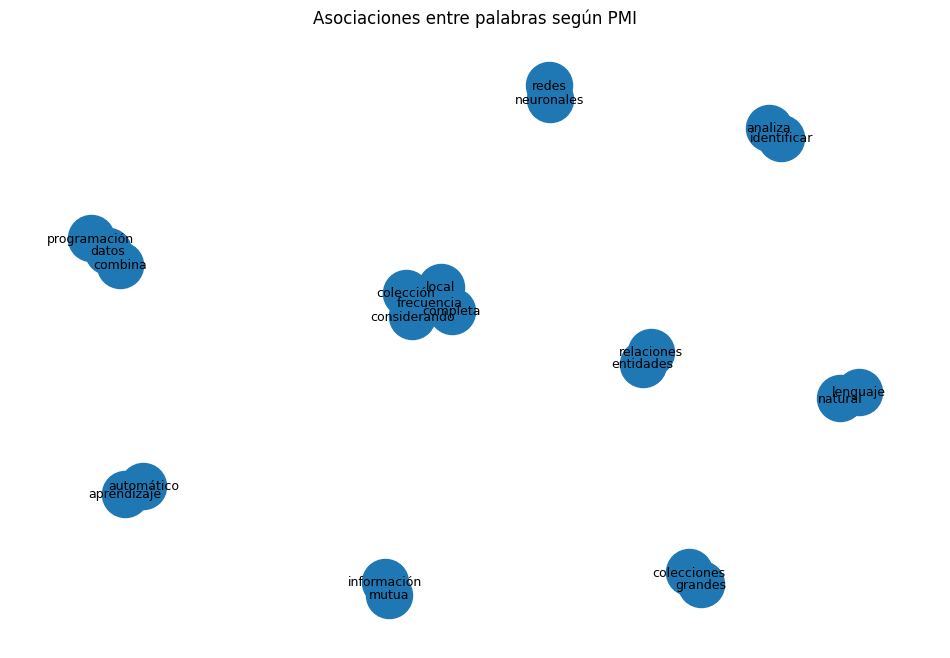

In [10]:
def grafo_asociaciones(tabla, pmi_min=4.0, max_aristas=25):
    seleccion = tabla[tabla["PMI"] >= pmi_min].head(max_aristas)

    G = nx.Graph()

    for _, fila in seleccion.iterrows():
        G.add_edge(
            fila["palabra_1"],
            fila["palabra_2"],
            weight=float(fila["PMI"])
        )

    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx_nodes(G, pos, node_size=1100)
    nx.draw_networkx_edges(G, pos, alpha=0.6)
    nx.draw_networkx_labels(G, pos, font_size=9)

    plt.title("Asociaciones entre palabras según PMI")
    plt.axis("off")
    plt.show()

    return G

G = grafo_asociaciones(tabla_pmi, pmi_min=4.0, max_aristas=25)


### Ejercicio 2

Selecciona tres asociaciones con PMI alto y explica por qué tienen sentido dentro del corpus.

Después localiza una asociación con frecuencia alta pero PMI relativamente menor.

Responde:

1-. aprendizaje – automático : forman un término compuesto, "aprendizaje automático". Casi nunca aparece una sin la otra, por eso su coocurrencia es mucho mayor entonce no es azar.

2-. lenguaje – natural : es compuesto, "lenguaje natural", un área completa de la IA. Cada palabra aparece poco en el corpus, pero cuando aparecen van juntas.

3-. información – mutua : por que ninguna de las dos palabras aparece por separado en otros contextos.

análisis – datos :queda en el lugar 23 de 27 por PMI, aunque empata en frecuencia con aprendizaje–automático (PMI 5.09). datos y análisis son palabras muy comunes en el corpus, así que aparecer juntas ya se esperaba por pura frecuencia individual.

1. ¿Por qué la frecuencia conjunta y PMI no producen siempre el mismo orden?
la frecuencia conjunta nomas cuenta cuantas veces aparecen juntas dos palabras. el detalle con eso es que las palabras súper comunenes.
siempre van a quedar hasta arriba nomas porque salen a cada rato en cualquier texto y  PMI va a sacar relaciones reales porque castiga a esas palabras que salen en todos lados lo que hace es comparar que tan seguido salen juntas contra que tan seguido salen cada una por su lado.
2. ¿Qué problema puede aparecer cuando una pareja ocurre pocas veces pero obtiene PMI alto? que puede ser pura coincidencia y no puede representar una similitud solo ser pura coinsidencia, y como hay muy poca frecuencia asume que son similares
3. ¿Por qué conviene establecer una coocurrencia mínima? por que limitas coinsidencias entonces tiene que repetir varias veces la coincidencia para asumir que son similares


In [11]:
tabla_pmi.head(30).round(3)


,palabra_1,palabra_2,coocurrencia,PMI
0,analiza,identificar,2,5.677
1,considerando,frecuencia,2,5.677
2,frecuencia,local,2,5.677
3,colección,frecuencia,2,5.677
4,completa,frecuencia,2,5.677
5,aprendizaje,automático,3,5.092
6,colecciones,grandes,2,5.092
7,neuronales,redes,2,5.092
8,información,mutua,2,5.092
9,entidades,relaciones,2,4.677


## 6. Actividad 3. Terminología

### Qué se hará

Se buscarán expresiones que pueden representar conceptos propios del dominio.

Se extraerán unigramas, bigramas y trigramas. Después se calculará TF IDF para valorar si una expresión caracteriza ciertos documentos mejor que otros.

Las expresiones de varias palabras son especialmente útiles porque muchos términos técnicos son compuestos, por ejemplo `aprendizaje automático`, `lenguaje natural` o `minería de datos`.


In [12]:
def preprocesar_para_vectorizador(texto):
    return " ".join(tokenizar(texto))

corpus_limpio = [preprocesar_para_vectorizador(t) for t in documentos]

vectorizador_terminos = TfidfVectorizer(
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.85
)

X_terminos = vectorizador_terminos.fit_transform(corpus_limpio)
terminos = np.array(vectorizador_terminos.get_feature_names_out())

promedio_tfidf = np.asarray(X_terminos.mean(axis=0)).ravel()
maximo_tfidf = np.asarray(X_terminos.max(axis=0).toarray()).ravel()
frecuencia_documental = np.asarray((X_terminos > 0).sum(axis=0)).ravel()

tabla_terminos = pd.DataFrame({
    "termino": terminos,
    "documentos_en_que_aparece": frecuencia_documental,
    "tfidf_promedio": promedio_tfidf,
    "tfidf_maximo": maximo_tfidf
})

tabla_terminos["numero_palabras"] = tabla_terminos["termino"].str.split().str.len()

tabla_terminos = tabla_terminos.sort_values(
    ["numero_palabras", "tfidf_maximo"],
    ascending=[False, False]
)

tabla_terminos.head(30).round(4)


,termino,documentos_en_que_aparece,tfidf_promedio,tfidf_maximo,numero_palabras
39,palabras aparecen,2,0.0316,0.5099,2
29,información mutua,2,0.0306,0.4993,2
31,lenguaje natural,3,0.0397,0.4988,2
50,representan palabras,2,0.0253,0.4395,2
4,aprendizaje automático,3,0.0356,0.4246,2
46,redes neuronales,2,0.0253,0.4140,2
7,ciencia datos,2,0.0254,0.4037,2
26,grandes colecciones,2,0.0237,0.3921,2
33,modelos,4,0.0730,1.0000,1
23,frecuencia,3,0.0601,0.9525,1


In [13]:
terminos_compuestos = tabla_terminos[
    tabla_terminos["numero_palabras"] >= 2
].sort_values(
    "tfidf_maximo",
    ascending=False
).reset_index(drop=True)

terminos_compuestos.head(25).round(4)


,termino,documentos_en_que_aparece,tfidf_promedio,tfidf_maximo,numero_palabras
0,palabras aparecen,2,0.0316,0.5099,2
1,información mutua,2,0.0306,0.4993,2
2,lenguaje natural,3,0.0397,0.4988,2
3,representan palabras,2,0.0253,0.4395,2
4,aprendizaje automático,3,0.0356,0.4246,2
5,redes neuronales,2,0.0253,0.4140,2
6,ciencia datos,2,0.0254,0.4037,2
7,grandes colecciones,2,0.0237,0.3921,2


### Comparación con frecuencia pura

La frecuencia indica cuánto aparece una expresión.

TF IDF incorpora también en cuántos documentos aparece. Una expresión muy frecuente en un documento pero poco común en el resto puede recibir un peso alto.


In [14]:
vectorizador_freq = CountVectorizer(
    ngram_range=(2, 3),
    min_df=2
)

X_freq = vectorizador_freq.fit_transform(corpus_limpio)
terminos_freq = vectorizador_freq.get_feature_names_out()
freq_total = np.asarray(X_freq.sum(axis=0)).ravel()

tabla_frecuencia_terminos = pd.DataFrame({
    "termino": terminos_freq,
    "frecuencia_total": freq_total
}).sort_values(
    "frecuencia_total",
    ascending=False
)

tabla_frecuencia_terminos.head(20)


,termino,frecuencia_total
0,aprendizaje automático,3
4,lenguaje natural,3
2,grandes colecciones,2
1,ciencia datos,2
3,información mutua,2
5,palabras aparecen,2
6,redes neuronales,2
7,representan palabras,2


### Ejercicio 3

Selecciona diez candidatos a término y clasifícalos manualmente como `Término técnico`, `Expresión relacionada` o `Ruido`.

Responde:

1. ¿Qué candidatos aparecen bien posicionados tanto por frecuencia como por TF IDF?lenguaje natural,aprendisaje automatico
2. ¿Qué candidatos cambian mucho de posición?palabras aparecen,grande coleccion,informacion mutua
3. ¿Por qué una expresión de varias palabras puede ser más específica? por que puede representar mas especifico que una palabra sola
4. ¿Por qué la extracción automática requiere revisión humana? por que puede cometer errores como extraer cosas muy similares , palabras que no aportan inforcion.


In [15]:

vect_extra = TfidfVectorizer(ngram_range=(2, 3), min_df=1, max_df=0.85)
X_extra = vect_extra.fit_transform(corpus_limpio)
extra = pd.DataFrame({
    "termino": vect_extra.get_feature_names_out(),
    "tfidf_maximo": np.asarray(X_extra.max(axis=0).toarray()).ravel()
})
extra = extra[extra["termino"].isin(["palabras clave", "algoritmo puede"])]

revision = pd.concat(
    [terminos_compuestos.head(8)[["termino", "tfidf_maximo"]], extra],
    ignore_index=True
)

clasificacion = {
    "palabras aparecen": "Ruido",
    "información mutua": "Término técnico",
    "lenguaje natural": "Término técnico",
    "representan palabras": "Expresión relacionada",
    "aprendizaje automático": "Término técnico",
    "redes neuronales": "Término técnico",
    "ciencia datos": "Término técnico",
    "grandes colecciones": "Expresión relacionada",
    "palabras clave": "Término técnico",
    "algoritmo puede": "Ruido",
}

revision["clasificacion_manual"] = revision["termino"].map(clasificacion)
revision.round(4)

,termino,tfidf_maximo,clasificacion_manual
0,palabras aparecen,0.5099,Ruido
1,información mutua,0.4993,Término técnico
2,lenguaje natural,0.4988,Término técnico
3,representan palabras,0.4395,Expresión relacionada
4,aprendizaje automático,0.4246,Término técnico
5,redes neuronales,0.4140,Término técnico
6,ciencia datos,0.4037,Término técnico
7,grandes colecciones,0.3921,Expresión relacionada
8,algoritmo puede,0.2582,Ruido
9,palabras clave,0.2582,Término técnico


## 7. Actividad 4. Palabras clave

### Qué se hará

Se obtendrán palabras clave con dos métodos distintos.

TF IDF utiliza la distribución estadística de las palabras en la colección.

TextRank construye una red de palabras y asigna mayor peso a aquellas que ocupan posiciones relevantes dentro de las conexiones del documento.

La finalidad es comparar resultados y entender por qué dos métodos pueden seleccionar palabras diferentes.


In [16]:
vectorizador_kw = TfidfVectorizer(
    tokenizer=tokenizar,
    token_pattern=None,
    lowercase=False
)

X_kw = vectorizador_kw.fit_transform(documentos)
vocab_kw = np.array(vectorizador_kw.get_feature_names_out())

def keywords_tfidf(indice_documento, top_n=8):
    fila = X_kw[indice_documento].toarray().ravel()
    orden = np.argsort(fila)[::-1]

    resultados = []
    for i in orden:
        if fila[i] <= 0:
            continue

        resultados.append({
            "palabra": vocab_kw[i],
            "peso_tfidf": round(float(fila[i]), 4)
        })

        if len(resultados) == top_n:
            break

    return pd.DataFrame(resultados)

indice_documento = 3
print(documentos[indice_documento])
keywords_tfidf(indice_documento, 8)


El procesamiento de lenguaje natural analiza textos para identificar patrones lingüísticos entidades relaciones y significado.


,palabra,peso_tfidf
0,significado,0.3401
1,procesamiento,0.3401
2,lingüísticos,0.3401
3,analiza,0.3032
4,entidades,0.3032
5,identificar,0.3032
6,patrones,0.3032
7,textos,0.2770


### TextRank simplificado

Se construirá una red con las palabras del documento.

Dos palabras quedarán conectadas cuando aparezcan dentro de la misma ventana de contexto.

Después se aplicará PageRank. Una palabra recibe mayor puntuación cuando está conectada con otras palabras relevantes dentro de la red.


In [17]:
def keywords_textrank(texto, ventana=3, top_n=8):
    tokens = tokenizar(texto)
    G = nx.Graph()

    for token in tokens:
        G.add_node(token)

    for i, palabra in enumerate(tokens):
        fin = min(len(tokens), i + ventana + 1)

        for j in range(i + 1, fin):
            otra = tokens[j]

            if palabra == otra:
                continue

            if G.has_edge(palabra, otra):
                G[palabra][otra]["weight"] += 1
            else:
                G.add_edge(palabra, otra, weight=1)

    if len(G) == 0:
        return pd.DataFrame({"palabra": [], "pagerank": []})

    scores = nx.pagerank(G, weight="weight")
    resultados = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:top_n]

    return pd.DataFrame(resultados, columns=["palabra", "pagerank"])

keywords_textrank(documentos[indice_documento], ventana=3, top_n=8).round(4)


,palabra,pagerank
0,lingüísticos,0.1085
1,analiza,0.1085
2,patrones,0.1068
3,textos,0.1068
4,identificar,0.1063
5,entidades,0.0930
6,natural,0.0930
7,relaciones,0.0773


### Comparación de métodos

Se compararán las listas obtenidas por TF IDF y TextRank para el mismo documento.


In [18]:
kw_tfidf = keywords_tfidf(indice_documento, 8)
kw_textrank = keywords_textrank(documentos[indice_documento], 3, 8)

comparacion = pd.DataFrame({
    "TF_IDF": kw_tfidf["palabra"],
    "TextRank": kw_textrank["palabra"]
})

comparacion


,TF_IDF,TextRank
0,significado,lingüísticos
1,procesamiento,analiza
2,lingüísticos,patrones
3,analiza,textos
4,entidades,identificar
5,identificar,entidades
6,patrones,natural
7,textos,relaciones


### Ejercicio 4

Selecciona cinco documentos diferentes y compara sus palabras clave.

Para cada documento responde:

1. ¿Qué palabras aparecen en ambos métodos?texto,analiza,lingüisticos,patronesidentificar,entidades
2. ¿Qué palabras aparecen únicamente en TF IDF?significado,procesamiento
3. ¿Qué palabras aparecen únicamente en TextRank?natural,relaciones
4. ¿Cuál método representa mejor ese documento y por qué?textrank ya que tiene mas palabras que representan mejor a el texto . adiferencia del otro que son palabras que lo representan bien pero puede ser un poco ambiguo como "significado"
5. ¿Cambiaría tu interpretación si el corpus tuviera miles de documentos?si ya que tf idf toma todo el corpus y saca el contexto, y textrank solo analisa las realcioes internas


In [19]:
docs_ej4 = [0, 3, 7, 10, 27]

for d in docs_ej4:
    print("=" * 70)
    print(f"Documento (índice {d}):")
    print(documentos[d])

    kw_a = keywords_tfidf(d, 8)
    kw_b = keywords_textrank(documentos[d], ventana=3, top_n=8)

    print("\nTF IDF")
    display(kw_a)
    print("TextRank")
    display(kw_b.round(4))

    a, b = set(kw_a["palabra"]), set(kw_b["palabra"])
    print("En ambos:       ", sorted(a & b))
    print("Solo TF IDF:    ", sorted(a - b))
    print("Solo TextRank:  ", sorted(b - a))


Documento (índice 0):
La ciencia de datos combina programación estadística análisis de datos y aprendizaje automático para resolver problemas complejos.

TF IDF


,palabra,peso_tfidf
0,datos,0.3656
1,programación,0.3208
2,problemas,0.3208
3,combina,0.3208
4,complejos,0.3208
5,resolver,0.3208
6,estadística,0.2861
7,ciencia,0.2861


TextRank


,palabra,pagerank
0,datos,0.1545
1,automático,0.1014
2,aprendizaje,0.0987
3,programación,0.0967
4,análisis,0.0965
5,estadística,0.0954
6,resolver,0.0873
7,combina,0.0831


En ambos:        ['combina', 'datos', 'estadística', 'programación', 'resolver']
Solo TF IDF:     ['ciencia', 'complejos', 'problemas']
Solo TextRank:   ['análisis', 'aprendizaje', 'automático']
Documento (índice 3):
El procesamiento de lenguaje natural analiza textos para identificar patrones lingüísticos entidades relaciones y significado.

TF IDF


...

En ambos:        ['anómalos', 'comportamientos', 'identificar', 'intrusiones', 'posibles', 'tráfico']
Solo TF IDF:     ['ataques', 'detección']
Solo TextRank:   ['analiza', 'red']
Documento (índice 27):
TextRank representa palabras como nodos de un grafo y utiliza sus conexiones para estimar importancia dentro de un texto.

TF IDF


,palabra,peso_tfidf
0,utiliza,0.3452
1,textrank,0.3452
2,representa,0.3452
3,grafo,0.3452
4,conexiones,0.3452
5,importancia,0.3452
6,texto,0.3077
7,estimar,0.2812


TextRank


,palabra,pagerank
0,nodos,0.1216
1,conexiones,0.1216
2,grafo,0.1201
3,utiliza,0.1201
4,palabras,0.1039
5,estimar,0.1039
6,representa,0.0862
7,importancia,0.0862


En ambos:        ['conexiones', 'estimar', 'grafo', 'importancia', 'representa', 'utiliza']
Solo TF IDF:     ['texto', 'textrank']
Solo TextRank:   ['nodos', 'palabras']


## 8. Actividad integradora

### Qué se hará

Se analizará un texto nuevo usando los cuatro componentes de la práctica.

La finalidad es pasar de resultados aislados a una interpretación conjunta del contenido semántico.


In [20]:
texto_nuevo = (
    "Los modelos de lenguaje y las redes neuronales permiten analizar grandes colecciones "
    "de documentos. La extracción de palabras clave y términos técnicos ayuda a resumir "
    "el contenido y a identificar relaciones semánticas entre conceptos."
)

tokens_nuevo = tokenizar(texto_nuevo)

print("Tokens del nuevo documento:")
print(tokens_nuevo)


Tokens del nuevo documento:
['modelos', 'lenguaje', 'redes', 'neuronales', 'permiten', 'analizar', 'grandes', 'colecciones', 'documentos', 'extracción', 'palabras', 'clave', 'términos', 'técnicos', 'ayuda', 'resumir', 'contenido', 'identificar', 'relaciones', 'semánticas', 'conceptos']


In [21]:
print("Palabras del texto presentes en el vocabulario semántico:")

for palabra in tokens_nuevo:
    if palabra in indice:
        print("\nPalabra:", palabra)
        display(palabras_similares(palabra, 5))


Palabras del texto presentes en el vocabulario semántico:

Palabra: modelos


,palabra,similitud
0,automático,0.669
1,análisis,0.590
2,estadística,0.571
3,aprendizaje,0.545
4,contextos,0.531



Palabra: lenguaje


,palabra,similitud
0,natural,0.695
1,ciencia,0.630
2,identificar,0.579
3,analiza,0.473
4,textos,0.461



Palabra: redes


...

,palabra,similitud
0,analiza,0.734
1,textos,0.624
2,patrones,0.613
3,lenguaje,0.579
4,natural,0.455



Palabra: relaciones


,palabra,similitud
0,entidades,0.795
1,semánticos,0.588
2,permiten,0.580
3,textos,0.513
4,representan,0.465



Palabra: conceptos


,palabra,similitud
0,extracción,0.834
1,expresiones,0.797
2,representan,0.677
3,términos,0.545
4,ciencia,0.440


In [22]:
print("Palabras clave con TextRank")
display(keywords_textrank(texto_nuevo, ventana=3, top_n=10).round(4))


Palabras clave con TextRank


,palabra,pagerank
0,neuronales,0.0541
1,identificar,0.0541
2,permiten,0.0526
3,contenido,0.0526
4,resumir,0.0515
5,analizar,0.0515
6,grandes,0.0508
7,ayuda,0.0508
8,colecciones,0.0502
9,técnicos,0.0502


### Ejercicio 5

Sustituye `texto_nuevo` por un texto técnico de entre 150 y 250 palabras relacionado con ingeniería en sistemas computacionales.

Realiza lo siguiente:

1. Obtén palabras similares para al menos cinco términos.
2. Busca asociaciones fuertes relacionadas con esos términos.
3. Identifica al menos diez candidatos a términos técnicos.
4. Extrae diez palabras clave con TF IDF y diez con TextRank.
5. Explica qué método produce resultados más útiles para tu texto.
6. Identifica al menos tres resultados incorrectos o poco útiles y explica por qué aparecen.


In [23]:
texto_nuevo = (
    "Un sistema computacional está formado por hardware, software y redes que trabajan juntos para procesar información. "
    "En la ingeniería de sistemas, la seguridad informática es fundamental: el diseño de una red segura requiere autenticación, cifrado y monitoreo constante del tráfico para detectar ataques. "
    "Los sistemas distribuidos reparten el trabajo entre varios nodos, de modo que si un servidor falla, otro puede continuar el procesamiento de los datos. "
    "En los sistemas distribuidos la seguridad informática es aún más importante, porque cada nodo es un posible punto de ataque. "
    "Hoy se utilizan modelos de aprendizaje automático para analizar grandes volúmenes de datos y predecir fallas antes de que ocurran. "
    "El aprendizaje automático se entrena con datos históricos y se evalúa con métricas como precisión y exactitud. "
    "El análisis de datos ayuda a identificar patrones de comportamiento, y las bases de datos almacenan la información y permiten consultarla de forma eficiente. "
    "Un algoritmo bien diseñado reduce el tiempo de respuesta y el consumo de recursos. "
    "Por eso, el análisis de datos y las bases de datos son parte esencial de la ingeniería de sistemas."
)
print("Palabras del texto:", len(texto_nuevo.split()))

tokens_nuevo = tokenizar(texto_nuevo)
terminos_ej5 = ["datos", "redes", "sistemas", "modelos", "información", "análisis"]

# 1. Palabras similares
for p in terminos_ej5:
    print(f"\n=== {p} ===")
    display(palabras_similares(p, 6))

# 2. Asociaciones fuertes
print("\nAsociaciones PMI en el corpus original (términos del ejercicio):")
mask = tabla_pmi["palabra_1"].isin(terminos_ej5) | tabla_pmi["palabra_2"].isin(terminos_ej5)
display(tabla_pmi[mask].round(3))

print("\nAsociaciones PMI dentro del texto nuevo (ventana 4, min_cooc 2):")
tabla_pmi_nuevo = asociaciones_pmi([tokens_nuevo], ventana=4, min_cooc=2)
display(tabla_pmi_nuevo.head(15).round(3))

Palabras del texto: 181

=== datos ===


,palabra,similitud
0,análisis,0.717
1,ciencia,0.683
2,entrenamiento,0.641
3,aprendizaje,0.581
4,automático,0.566
5,evaluación,0.565



=== redes ===


,palabra,similitud
0,texto,0.702
1,automático,0.678
2,neuronales,0.677
3,análisis,0.607
4,aprendizaje,0.462
5,representaciones,0.429



=== sistemas ===


...

,palabra,similitud
0,datos,0.717
1,automático,0.713
2,aprendizaje,0.621
3,redes,0.607
4,modelos,0.590
5,estadística,0.513



Asociaciones PMI en el corpus original (términos del ejercicio):


,palabra_1,palabra_2,coocurrencia,PMI
7,neuronales,redes,2,5.092
8,información,mutua,2,5.092
11,combina,datos,2,4.355
12,datos,programación,2,4.355
13,datos,estadística,3,3.940
14,análisis,redes,2,3.770
15,ciencia,datos,2,3.355
16,datos,evaluación,2,3.355
19,automático,datos,2,2.770
22,análisis,datos,3,2.618



Asociaciones PMI dentro del texto nuevo (ventana 4, min_cooc 2):


,palabra_1,palabra_2,coocurrencia,PMI
0,informática,seguridad,2,3.712
1,aprendizaje,automático,2,3.712
2,datos,ocurran,2,2.905
3,datos,métricas,2,2.905
4,datos,precisión,2,2.905
5,datos,identificar,2,2.905
6,datos,patrones,2,2.905
7,comportamiento,datos,2,2.905
8,datos,recursos,2,2.905
9,datos,esencial,2,2.905


In [24]:
docs_ext = documentos + [texto_nuevo]
vec_kw5 = TfidfVectorizer(tokenizer=tokenizar, token_pattern=None, lowercase=False)
X_kw5 = vec_kw5.fit_transform(docs_ext)
vocab_kw5 = np.array(vec_kw5.get_feature_names_out())

fila = X_kw5[len(docs_ext) - 1].toarray().ravel()
orden = np.argsort(fila)[::-1][:10]
kw_tfidf_5 = pd.DataFrame({"palabra": vocab_kw5[orden], "peso_tfidf": fila[orden].round(4)})
kw_tr_5 = keywords_textrank(texto_nuevo, ventana=3, top_n=10).round(4)

print("TF IDF")
display(kw_tfidf_5)
print("TextRank")
display(kw_tr_5)

a, b = set(kw_tfidf_5["palabra"]), set(kw_tr_5["palabra"])
print("En ambos:      ", sorted(a & b))
print("Solo TF IDF:   ", sorted(a - b))
print("Solo TextRank: ", sorted(b - a))

TF IDF


,palabra,peso_tfidf
0,datos,0.3559
1,sistemas,0.2809
2,bases,0.1855
3,distribuidos,0.1656
4,seguridad,0.1656
5,informática,0.1656
6,ingeniería,0.1656
7,información,0.1405
8,aprendizaje,0.1405
9,automático,0.1405


TextRank


,palabra,pagerank
0,datos,0.0553
1,sistemas,0.0298
2,aprendizaje,0.0183
3,información,0.0183
4,automático,0.0182
5,distribuidos,0.0180
6,informática,0.0179
7,análisis,0.0177
8,seguridad,0.0175
9,bases,0.0173


En ambos:       ['aprendizaje', 'automático', 'bases', 'datos', 'distribuidos', 'información', 'informática', 'seguridad', 'sistemas']
Solo TF IDF:    ['ingeniería']
Solo TextRank:  ['análisis']


5. ¿Qué método produce resultados más útiles?

Los dos coinciden en 9 de las 10 palabras, así que para este texto la diferencia es pequeña. TF IDF

6. Resultados incorrectos o poco útiles?

Similares sin relación con sistemas: "redes" sale cercana a "texto" (0.70) y "sistemas" a "estudia"

## 9. Retos

La última parte requiere modificar parámetros y justificar decisiones. No basta con ejecutar el código.


### Reto A. Sensibilidad a la ventana de contexto

Construye tres modelos de coocurrencia con ventanas de 2, 4 y 7 palabras.

Compara las diez palabras más similares a un mismo término.

Calcula cuántas palabras se repiten entre las tres listas y explica qué tipo de relación parece capturar cada ventana.


### Reto B. Estabilidad de las palabras clave

Selecciona cinco documentos y extrae palabras clave con TF IDF y TextRank.

Elimina uno de los documentos del corpus y vuelve a calcular TF IDF.

Compara el resultado anterior y el nuevo. Explica por qué TF IDF puede cambiar aunque el documento analizado no se modifique.


### Reto C. Diseño de un criterio de términos

Crea una puntuación propia para candidatos a término usando al menos frecuencia total, frecuencia documental, longitud del término y TF IDF.

Define la fórmula, explica qué busca favorecer y muestra los quince términos mejor puntuados.


In [25]:
#reto A
palabra_reto = "lenguaje"
modelos_reto = {v: modelo_por_ventana(v) for v in (2, 4, 7)}

listas = {}
for v, m in modelos_reto.items():
    res = similares_ventana(palabra_reto, m, 10)
    listas[v] = [p for p, _ in res]
    print(f"ventana {v}: {listas[v]}")

comunes = set(listas[2]) & set(listas[4]) & set(listas[7])
print("\nEn las tres ventanas:", sorted(comunes), f"({len(comunes)} de 10)")
print("Solo en ventana 2:", sorted(set(listas[2]) - set(listas[4]) - set(listas[7])))
print("Solo en ventana 7:", sorted(set(listas[7]) - set(listas[2]) - set(listas[4])))
print("Repetidas 2 y 4:", len(set(listas[2]) & set(listas[4])),
      "| 4 y 7:", len(set(listas[4]) & set(listas[7])),
      "| 2 y 7:", len(set(listas[2]) & set(listas[7])))


ventana 2: ['términos', 'estadística', 'datos', 'textos', 'análisis', 'identificar', 'permite', 'analiza', 'natural', 'red']
ventana 4: ['natural', 'patrones', 'ciencia', 'identificar', 'analiza', 'red', 'palabras', 'textos', 'entidades', 'representan']
ventana 7: ['natural', 'textos', 'analiza', 'identificar', 'relaciones', 'entidades', 'patrones', 'contextos', 'red', 'ciencia']

En las tres ventanas: ['analiza', 'identificar', 'natural', 'red', 'textos'] (5 de 10)
Solo en ventana 2: ['análisis', 'datos', 'estadística', 'permite', 'términos']
Solo en ventana 7: ['contextos', 'relaciones']
Repetidas 2 y 4: 5 | 4 y 7: 8 | 2 y 7: 5


Se repiten 5 de 10 palabras en las tres ventanas, y las más estables natural, textos, analiza, identificar son las que van junto a "lenguaje" en la oración de procesamiento de lenguaje natural. La ventana 2 mete palabras más débiles términos, estadística, datos, permite, porque con un corpus tan chico hay pocas coocurrencias y los vecinos inmediatos salen ruidosos. Las ventanas 4 y 7 se parecen mucho entre sí 8 compartidas y capturan relaciones más temáticas entidades, patrones, relaciones, contextos, que son palabras de la misma oración aunque no estén pegadas.

#B

In [26]:
docs_reto_b = [0, 3, 7, 10, 27]
doc_quitado = 1

corpus_nuevo = [d for k, d in enumerate(documentos) if k != doc_quitado]

def tfidf_top(corpus, indice, top_n=8):
    vec = TfidfVectorizer(tokenizer=tokenizar, token_pattern=None, lowercase=False)
    X = vec.fit_transform(corpus)
    vocab = np.array(vec.get_feature_names_out())
    fila = X[indice].toarray().ravel()
    orden = np.argsort(fila)[::-1]
    return [(vocab[i], round(float(fila[i]), 4)) for i in orden if fila[i] > 0][:top_n]

for d in docs_reto_b:
    d_nuevo = d if d < doc_quitado else d - 1
    antes = tfidf_top(documentos, d)
    despues = tfidf_top(corpus_nuevo, d_nuevo)
    pa, pd_ = {p for p, _ in antes}, {p for p, _ in despues}

    print("=" * 70)
    print(documentos[d])
    print("TF IDF antes:  ", antes)
    print("TF IDF después:", despues)
    print("Salen del top 8:", sorted(pa - pd_), "| Entran:", sorted(pd_ - pa))
    print("TextRank (no depende del corpus):",
          list(keywords_textrank(documentos[d], 3, 8)["palabra"]))

La ciencia de datos combina programación estadística análisis de datos y aprendizaje automático para resolver problemas complejos.
TF IDF antes:   [('datos', 0.3656), ('programación', 0.3208), ('problemas', 0.3208), ('combina', 0.3208), ('complejos', 0.3208), ('resolver', 0.3208), ('estadística', 0.2861), ('ciencia', 0.2861)]
TF IDF después: [('datos', 0.3744), ('programación', 0.3149), ('problemas', 0.3149), ('combina', 0.3149), ('resolver', 0.3149), ('complejos', 0.3149), ('estadística', 0.2805), ('automático', 0.2805)]
Salen del top 8: ['ciencia'] | Entran: ['automático']
TextRank (no depende del corpus): ['datos', 'automático', 'aprendizaje', 'programación', 'análisis', 'estadística', 'resolver', 'combina']
El procesamiento de lenguaje natural analiza textos para identificar patrones lingüísticos entidades relaciones y significado.
TF IDF antes:   [('significado', 0.3401), ('procesamiento', 0.3401), ('lingüísticos', 0.3401), ('analiza', 0.3032), ('entidades', 0.3032), ('identificar

TF IDF cambia aunque el documento no se modifique porque el IDF depende de todo el corpus: al quitar un documento cambian N y el número de documentos donde aparece cada palabra. En este caso "automático" aparecía en menos documentos, subió su IDF y entró al top de los docs 0 y 7. Además, TF IDF se normaliza por documento, así que cuando cambian unos pesos cambian todos un poco. TextRank no cambia porque solo usa el grafo del propio documento.

#C

In [27]:
N = len(corpus_limpio)

vec_c = TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.85)
X_c = vec_c.fit_transform(corpus_limpio)
terminos_c = vec_c.get_feature_names_out()

conteo = CountVectorizer(ngram_range=(1, 3), vocabulary=terminos_c).fit_transform(corpus_limpio)

reto_c = pd.DataFrame({
    "termino": terminos_c,
    "frecuencia_total": np.asarray(conteo.sum(axis=0)).ravel(),
    "documentos": np.asarray((conteo > 0).sum(axis=0)).ravel(),
    "tfidf_maximo": np.asarray(X_c.max(axis=0).toarray()).ravel(),
})
reto_c["numero_palabras"] = reto_c["termino"].str.split().str.len()

reto_c["puntuacion_propia"] = (
    reto_c["tfidf_maximo"]
    * (1 + np.log(reto_c["frecuencia_total"]))
    * reto_c["numero_palabras"] ** 2
    * (1 - reto_c["documentos"] / N)
)

reto_c.sort_values("puntuacion_propia", ascending=False).head(15).round(3)

,termino,frecuencia_total,documentos,tfidf_maximo,numero_palabras,puntuacion_propia
31,lenguaje natural,3,3,0.499,2,3.768
39,palabras aparecen,2,2,0.510,2,3.223
4,aprendizaje automático,3,3,0.425,2,3.208
29,información mutua,2,2,0.499,2,3.156
50,representan palabras,2,2,0.440,2,2.778
46,redes neuronales,2,2,0.414,2,2.617
7,ciencia datos,2,2,0.404,2,2.552
26,grandes colecciones,2,2,0.392,2,2.478
33,modelos,4,4,1.000,1,2.068
23,frecuencia,4,3,0.952,1,2.046


TF-IDF máximo: términos que caracterizan bien al menos un documento.
1 + ln(frecuencia total): términos que se repiten en el corpus. Uso logaritmo para que una palabra muy repetida no domine la puntuación.
(número de palabras)²: expresiones compuestas, que suelen ser más específicas que una palabra suelta.
1 − documentos/N: castiga términos que aparecen en muchos documentos, porque son demasiado generales para ser técnicos.los ocho primeros lugares son expresiones de dos palabras: lenguaje natural, palabras aparecen , aprendizaje automático , información mutua , representan palabras, redes neuronales, ciencia datos y grandes colecciones. Después aparecen palabras sueltas: modelos, frecuencia, representaciones, datos, grandes, sistemas y análisis. Esto muestra que el factor de longitud sí logra priorizar las expresiones compuestas.


### 10.1 Diferencia entre similitud y asociación

La **similitud** mide si dos palabras aparecen en contextos parecidos, es decir, si están rodeadas por las mismas palabras. Se calcula con la similitud coseno entre sus vectores (PPMI + SVD), y dos palabras muy similares no necesitan aparecer juntas. Por ejemplo, *datos* y *análisis* tienen similitud de 0.717, la más alta de *datos*.

La **asociación** mide si dos palabras aparecen juntas con mayor frecuencia de la esperada por azar. Se calcula con PMI sobre pares de palabras dentro de una ventana. Por ejemplo, *aprendizaje – automático* tiene PMI de 5.09 porque aparecen una junto a la otra casi siempre.

Las dos medidas no siempre coinciden. *análisis – datos* es una pareja muy similar pero con una asociación relativamente débil (PMI de 2.62, lugar 23 de 27), porque ambas son palabras frecuentes que aparecen con muchas otras y su cercanía ya se esperaba por frecuencia. En cambio, *aprendizaje – automático* es una asociación fuerte porque forma un término compuesto. En resumen, la similitud indica que dos palabras se usan de manera parecida, y la asociación indica que se usan juntas.

## 10. Entregables

La entrega debe incluir el notebook ejecutado y la interpretación de los resultados.

Incluye los resultados de los cinco ejercicios, los tres retos, una explicación de la diferencia entre similitud y asociación, una comparación entre términos y palabras clave, una justificación de los parámetros modificados y una reflexión técnica de entre 250 y 400 palabras sobre las limitaciones observadas.

La evaluación debe considerar tanto la ejecución correcta como la interpretación de los resultados.



### 10.1 Diferencia entre similitud y asociación

La **similitud** mide si dos palabras aparecen en contextos parecidos, es decir, si están rodeadas por las mismas palabras. Se calcula con la similitud coseno entre sus vectores (PPMI + SVD), y dos palabras muy similares no necesitan aparecer juntas. Por ejemplo, *datos* y *análisis* tienen similitud de 0.717, la más alta de *datos*.

La **asociación** mide si dos palabras aparecen juntas con mayor frecuencia de la esperada por azar. Se calcula con PMI sobre pares de palabras dentro de una ventana. Por ejemplo, *aprendizaje – automático* tiene PMI de 5.09 porque aparecen una junto a la otra casi siempre.

Las dos medidas no siempre coinciden. *análisis – datos* es una pareja muy similar pero con una asociación relativamente débil (PMI de 2.62, lugar 23 de 27), porque ambas son palabras frecuentes que aparecen con muchas otras y su cercanía ya se esperaba por frecuencia. En cambio, *aprendizaje – automático* es una asociación fuerte porque forma un término compuesto. En resumen, la similitud indica que dos palabras se usan de manera parecida, y la asociación indica que se usan juntas.

### 10.2 Comparación entre términos y palabras clave

Los **términos** son expresiones de una a tres palabras que representan conceptos del dominio. Se extraen mirando todo el corpus (n-gramas con TF IDF) y requieren revisión manual. Ejemplos de este corpus: *lenguaje natural*, *aprendizaje automático*, *redes neuronales*, *ciencia datos* e *información mutua*.

Las **palabras clave** resumen un documento en particular. Se obtuvieron con TF IDF (que compara el documento contra la colección) y con TextRank (que usa solo la red de palabras del propio documento). En el documento 3, por ejemplo, ambos métodos coincidieron en *analiza*, *entidades*, *identificar*, *lingüísticos*, *patrones* y *textos*.

Las diferencias principales son:
- **Alcance:** los términos se buscan en el corpus completo y las palabras clave se calculan por documento.
- **Unidad:** los términos suelen ser expresiones compuestas y las palabras clave de esta práctica son palabras sueltas.
- **Objetivo:** los términos identifican conceptos del dominio y las palabras clave describen de qué trata un documento.

Esto provoca que las palabras clave pierdan sentido por separado. En el documento 3, TextRank devuelve *natural* sin *lenguaje*, y sola no dice mucho; en cambio, la extracción de términos sí recupera la expresión completa *lenguaje natural*. Por eso los dos enfoques se complementan.

### 10.3 Justificación de los parámetros modificados

| Parámetro | Valor base | Valor usado | Justificación |
|---|---|---|---|
| Ventana de coocurrencia | 3 | 2 y 5 (Ejercicio 1); 2, 4 y 7 (Reto A) | Para ver cómo cambia el tipo de relación. La ventana pequeña captura vecinos inmediatos y la grande relaciones más temáticas. Como las oraciones son cortas, la ventana 7 ya cubre casi toda la oración. |
| `min_freq` del vocabulario | 2 | 2 | Se conserva para descartar palabras vistas una sola vez, cuyo vector sería ruido. El costo es que el vocabulario queda en 50 palabras y deja fuera términos como `modelo`. |
| Ventana y `min_cooc` del PMI | 4 y 2 | 4 y 2 | `min_cooc=2` evita pares que aparecen una sola vez, que inflan el PMI por casualidad. |
| `min_df` y `ngram_range` para términos | 2 y (1, 3) | `min_df=1` en dos candidatos extra (Ejercicio 3) | Con `min_df=2` solo había 8 expresiones y se pedían 10, así que se complementó con `palabras clave` y `algoritmo puede`. |
| Candidatos del Ejercicio 5 | (1, 3) | (2, 3) con `min_df=1` | Con un solo texto nuevo no hay frecuencia documental, así que se ordenó por repeticiones dentro del texto. |
| `top_n` de palabras clave | 8 | 10 (Ejercicio 5) | Lo pide el ejercicio. |
| Documento eliminado (Reto B) | ninguno | índice 1 | Comparte "aprendizaje automático" y "datos" con los documentos analizados, así que se nota el cambio en el IDF. |
| Puntuación del Reto C | TF IDF máximo | fórmula propia | Se agregó logaritmo a la frecuencia, longitud al cuadrado y penalización por frecuencia documental para priorizar expresiones compuestas y poco generales. |


### 10.4 Reflexión técnica y conclusión

Lo primero que noté en esta práctica es que casi todos los problemas vienen del tamaño del corpus. Con solo 30 oraciones y un vocabulario de 50 palabras que aparecen al menos dos veces, cualquier coincidencia pesa demasiado. Por eso "redes" quedó cerca de "texto" (0.70) y "sistemas" cerca de "estudia", cuando en realidad esas palabras no tienen una relación de significado, solo comparten una oración. Con PMI pasa algo parecido: la pareja "analiza – identificar" obtuvo el PMI más alto (5.68) y aparece apenas dos veces, así que no puedo afirmar que sea una asociación real.

Otra limitación fue la sensibilidad a los parámetros. Cuando cambié la ventana en el Reto A, solo 5 de las 10 palabras más similares a "lenguaje" se mantuvieron. Con TF IDF vi algo que no esperaba: al quitar un documento del corpus, "automático" entró al top de palabras clave de otros dos documentos que no toqué, porque cambió su IDF. TextRank no tuvo ese problema, pero tampoco aprovecha información de los demás documentos.

También me di cuenta de que el preprocesamiento pesa mucho. Al quitar stopwords se pierde el "de" y quedan términos como "bases datos" o "ciencia datos". Como no hay lematización, "modelo" y "modelos" cuentan como palabras distintas, y por eso "modelo" ni siquiera entró al vocabulario. Además, al unir todo el texto del Ejercicio 5 aparecieron expresiones que cruzan oraciones, como "ataque hoy utilizan".

Por último, los métodos automáticos se equivocan con mucha seguridad. "palabras aparecen" salió primera en TF IDF y segunda en mi fórmula del Reto C, y "modelos" tuvo un peso de 1.0 solo porque un documento se quedó con una única palabra válida. Ninguno de los dos resultados reflejaba algo útil, y solo me di cuenta al revisarlos a mano.

Mi conclusión es que estas técnicas sirven como una primera pista, no como respuesta final. Dan buenos resultados cuando hay frases repetidas y claras, como "lenguaje natural" o "aprendizaje automático", pero siempre necesitan un corpus más grande y alguien que revise lo que sale. Lo que más me llevo es que ejecutar el código es la parte fácil, lo difícil es interpretar si el resultado tiene sentido.